# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 33: Ensemble de Entradas — Diversidade, Equilíbrio e Voto

**Autor:** Evandro Rocha (UFRJ / COPPE / PEE)
**Data:** Outubro de 2026

---

Os Notebooks 30–32 mostraram que MEL, LOFAR, HHT e DEMON erram, em parte, gravações diferentes. Aqui perguntamos se essa diversidade vira acerto quando as entradas de um mesmo classificador são combinadas, e por que isso acontece em uma família e não em outras.

1. Qual família tem as entradas menos correlacionadas? Por que as medidas **sobre os erros** e **sobre as classes** apontam famílias diferentes?
2. As entradas de cada família têm desempenho equilibrado?
3. O **voto majoritário** das quatro entradas supera cada entrada isolada?
4. O melhor voto: BiGRU × MLP.
5. Uma **regra feita à mão** (MEL = MEDIUM e LOFAR/HHT = LARGE → SMALL) funciona?
6. Uma **tabela de combinações** (BKS) aprendida nos dados funciona?
7. Diversidade, equilíbrio e ganho.

**Resumo:**
- **Erros (Q, Y, κ de Fleiss):** a família com as entradas menos correlacionadas é a **BiGRU** (Q 0,60, κ de Fleiss 0,33); a mais correlacionada é a MLP (Q 0,68). As diferenças entre famílias são pequenas.
- **Classes (V, κ de Cohen):** o menor valor é do **SVM**, porque nele as entradas que erram juntas dizem classes diferentes com mais frequência (50% dos erros em comum, contra 35–45% nas outras famílias).
- **Voto das 4 entradas:** só no BiGRU o ganho sobre a melhor entrada é significativo (BiGRU: +3,12 pontos; p = 0,004). No BiGRU, o voto supera cada uma das quatro entradas sem correção (maior p = 0,006); com a correção de Holm para as 16 comparações, continua superando MEL, LOFAR, DEMON.
- **Melhor SP final:** voto MLP (67,04); BiGRU × MLP: Δ = -0,31, p = 0,661 (empate).
- **Regra MEDIUM/LARGE → SMALL:** quando o padrão aparece, a gravação é SMALL em só 25–39% dos casos (o mais comum é LARGE). Aplicá-la muda o SP em +0,08 a +0,29 pontos, sem significância.
- **BKS:** Δ de -1,88 a +2,47 pontos contra o MEL; 0 de 8 comparações significativas.
- **O que explica o ganho do voto:** diversidade dos erros **e** equilíbrio entre as entradas. A família em que o voto ganha é a que tem as duas coisas.

Predição por gravação = voto majoritário das janelas; todas as tabelas são calculadas na execução (`notebooks/src/iara_results.py`).

In [1]:
import os, sys, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.metrics import cohen_kappa_score
try:
    from IPython.display import display
except ImportError:
    display = print

for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 120})
pd.set_option('display.precision', 2); pd.set_option('display.width', 200)
CLS = R.CLASSES
SMALL, MEDIUM, LARGE = 0, 1, 2
REP = ['MEL', 'LOFAR', 'HHT', 'DEMON']

# 4 famílias × 4 entradas (os mesmos modelos dos Notebooks 30–32)
FAM = {
    'RF': ['rf_mel5s_n100_balanced_4c', 'rf_lofar5s_n100_balanced_4c', 'rf_hht_n100_balanced_4c', 'rf_demon_n100_balanced_4c'],
    'SVM': ['svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0', 'svm_nystroem_6000_lofar_elasticnet_l1r0.15',
            'svm_nystroem_6000_hht_C2.0_elasticnet_l1r0.15_4c', 'svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.15_it1000_4c'],
    'MLP': ['mlp', 'mlp_lofar', 'mlp_hht_h32-16_e30_4c', 'mlp_demon_h32-16_e30_4c'],
    'BiGRU': ['bigru_att_mel5s_h64_s15-5_e20_4c', 'bigru_att_lofar5s_h128_s15-5_e15_4c', 'bigru_att_hht_h64_s15-5_e20_4c',
              'bigru_att_demon_h64_s15-5_e20_4c'],
}
AL = {f: R.aligned(ex) for f, ex in FAM.items()}  # {família: {fold: DataFrame(File, Target, <exp>...)}}


def metr(y, p):
    """SP, ACC balanceada e recall por classe (mesma definição de iara_results)."""
    return R._metrics(np.asarray(y), np.asarray(p))


def voto(P, desempate):
    """Voto de pluralidade por linha de P (gravações × entradas); empate -> classe de 'desempate' se empatada,
    senão a menor classe empatada."""
    out = np.empty(len(P), dtype=int)
    for i, (row, d) in enumerate(zip(P, desempate)):
        c = np.bincount(row, minlength=4); top = np.flatnonzero(c == c.max())
        out[i] = d if d in top else top[0]
    return out


def por_fold(f, fn):
    """Aplica fn(df, ex) -> predição em cada fold da família f; devolve DataFrame de métricas por fold."""
    rows = []
    for k, d in AL[f].items():
        rows.append({'fold': k, **metr(d.Target.values, fn(d, FAM[f]))})
    return pd.DataFrame(rows).set_index('fold')


SOLO = {f: {r: por_fold(f, lambda d, ex, i=i: d[ex[i]].values) for i, r in enumerate(REP)} for f in FAM}
print('Gravações alinhadas por fold:', {f: int(np.mean([len(d) for d in AL[f].values()])) for f in FAM})

Gravações alinhadas por fold: {'RF': 639, 'SVM': 639, 'MLP': 639, 'BiGRU': 639}


## 1. Diversidade por família: erros × classes

Duas perguntas diferentes:

| Medida | Sobre | Pergunta |
|---|---|---|
| Q e Y de Yule, κ de Fleiss (acerto/erro) | acerto/erro | as entradas erram **as mesmas gravações**? |
| V de Cramér, κ de Cohen, κ de Fleiss (classes) | classe predita | as entradas dizem **a mesma classe**? |

Elas divergem num caso: duas entradas erram a mesma gravação SMALL, uma dizendo MEDIUM e a outra LARGE. Para o Q é **erro em comum**; para o κ de Cohen e o V é **discordância**. A coluna "erram juntas com classes diferentes" mede quantas vezes isso acontece.

Para ensembles, a pergunta relevante é a primeira (quando uma erra, a outra acerta?); é a que Kuncheva e Whitaker (2003) usam para medir diversidade.

In [2]:
def yule(ea, eb):
    n11, n00 = float((ea & eb).sum()), float((~ea & ~eb).sum())
    n10, n01 = float((ea & ~eb).sum()), float((~ea & eb).sum())
    ad, bc = n11 * n00, n10 * n01
    return (ad - bc) / (ad + bc), (np.sqrt(ad) - np.sqrt(bc)) / (np.sqrt(ad) + np.sqrt(bc))

def cramer_v(pa, pb):
    t = pd.crosstab(pa, pb).values
    return np.sqrt(chi2_contingency(t, correction=False)[0] / (t.sum() * (min(t.shape) - 1)))

def fleiss(M, n_cat):
    N, L = M.shape
    n = np.stack([(M == c).sum(1) for c in range(n_cat)], 1)
    pj = n.sum(0) / (N * L); Pi = (n * (n - 1)).sum(1) / (L * (L - 1)); Pe = np.sum(pj ** 2)
    return (Pi.mean() - Pe) / (1 - Pe)

rows, rows_f = [], []
for f, ex in FAM.items():
    for k, d in AL[f].items():
        y = d.Target.values
        P = np.stack([d[e].values for e in ex], 1); E = P != y[:, None]
        for i, j in itertools.combinations(range(4), 2):
            q, yy = yule(E[:, i], E[:, j])
            ambos = E[:, i] & E[:, j]
            rows.append({'Família': f, 'Par': f'{REP[i]} × {REP[j]}', 'fold': k, 'Q (erros)': q, 'Y (erros)': yy,
                         'V de Cramér (classes)': cramer_v(P[:, i], P[:, j]),
                         'κ de Cohen (classes)': cohen_kappa_score(P[:, i], P[:, j]),
                         'erram juntas com classes diferentes (%)': 100 * np.mean(P[ambos, i] != P[ambos, j]) if ambos.any() else np.nan})
        rows_f.append({'Família': f, 'fold': k, 'κ de Fleiss (acerto/erro)': fleiss((~E).astype(int), 2),
                       'κ de Fleiss (classes)': fleiss(P, 4)})
PAR = pd.DataFrame(rows).groupby(['Família', 'Par']).mean(numeric_only=True).drop(columns='fold')
DIV = PAR.groupby('Família').mean().reindex(list(FAM))
DIV = DIV.join(pd.DataFrame(rows_f).groupby('Família').mean().drop(columns='fold'))
print('Média dos 6 pares de entradas e κ de Fleiss das 4, por família:'); display(DIV.round(3))
QP = PAR['Q (erros)'].unstack('Família')[list(FAM)]
print('Q de Yule por par:'); display(QP.round(2))

Média dos 6 pares de entradas e κ de Fleiss das 4, por família:


,Q (erros),Y (erros),V de Cramér (classes),κ de Cohen (classes),erram juntas com classes diferentes (%),κ de Fleiss (acerto/erro),κ de Fleiss (classes)
Família,,,,,,,
RF,0.63,0.37,0.48,0.43,34.59,0.35,0.43
SVM,0.63,0.37,0.45,0.39,49.80,0.35,0.38
MLP,0.68,0.41,0.47,0.44,44.98,0.38,0.44
BiGRU,0.60,0.34,0.46,0.41,45.06,0.33,0.41


Q de Yule por par:


Família,RF,SVM,MLP,BiGRU
Par,,,,
HHT × DEMON,0.53,0.48,0.58,0.56
LOFAR × DEMON,0.47,0.68,0.57,0.47
LOFAR × HHT,0.83,0.62,0.80,0.63
MEL × DEMON,0.47,0.54,0.53,0.49
MEL × HHT,0.73,0.62,0.74,0.69
MEL × LOFAR,0.78,0.83,0.85,0.78


**Leitura.**
- **Pelos erros**, a ordem do menos ao mais correlacionado é: BiGRU (Q 0,60, Fleiss 0,33), SVM (Q 0,63, Fleiss 0,35), RF (Q 0,63, Fleiss 0,35), MLP (Q 0,68, Fleiss 0,38). A diferença entre BiGRU e as demais é pequena (o κ de Fleiss varia ~0,02 entre folds).
- **Pelas classes**, o menor κ de Cohen é do SVM (0,39) e o menor V é do SVM (0,45). No SVM, 50% das vezes em que duas entradas erram juntas elas dizem classes diferentes (média das outras famílias: 42%). Discordar na classe errando não é complementaridade.
- **O par que mais distingue o BiGRU é LOFAR × HHT:** Q RF 0,83, SVM 0,62, MLP 0,80, BiGRU 0,63. No RF e no MLP, LOFAR e HHT erram quase sempre juntas; no BiGRU, bem menos (coerente com a fusão BiGRU LOFAR + HHT, a única significativa do Notebook 30).

## 2. Equilíbrio: as entradas têm desempenho parecido?

In [3]:
EQ = pd.DataFrame({f: {r: SOLO[f][r].SP.mean() for r in REP} for f in FAM}).T
EQ['melhor'] = EQ[REP].max(axis=1); EQ['melhor entrada'] = EQ[REP].idxmax(axis=1)
EQ['pior'] = EQ[REP].min(axis=1); EQ['amplitude (melhor − pior)'] = EQ.melhor - EQ.pior
EQ['desvio entre entradas'] = EQ[REP].std(axis=1, ddof=0)
print('SP (%) de cada entrada sozinha (gravações alinhadas, média dos 10 folds):'); display(EQ.round(2))

SP (%) de cada entrada sozinha (gravações alinhadas, média dos 10 folds):


,MEL,LOFAR,HHT,DEMON,melhor,melhor entrada,pior,amplitude (melhor − pior),desvio entre entradas
RF,61.50,63.07,57.64,44.44,63.07,LOFAR,44.44,18.63,7.33
SVM,63.78,63.83,51.18,44.95,63.83,LOFAR,44.95,18.88,8.17
MLP,64.74,66.24,56.70,53.06,66.24,LOFAR,53.06,13.18,5.49
BiGRU,63.60,62.22,58.18,55.54,63.60,MEL,55.54,8.06,3.20


**Leitura.**
- Amplitude entre a melhor e a pior entrada: BiGRU 8,1 pontos, MLP 13,2 pontos, RF 18,6 pontos, SVM 18,9 pontos.
- A pior entrada é o DEMON em todas as famílias; no RF e no SVM ele fica perto de 45%.
- Num voto, uma entrada fraca "vota errado" com frequência; ela só ajuda se as outras errarem gravações diferentes **e** ela acertar parte delas.

## 3. Voto majoritário das quatro entradas

Para cada gravação, a classe final é a mais votada entre as quatro entradas da mesma família (empate → a classe do MEL, se empatada). Não há treino novo. Comparação com cada entrada isolada pelo F-test 5×2cv (Alpaydin, 1999). Como sensibilidade, o voto com empate sorteado (`iara_results.majority_vote`).

Voto majoritário das 4 entradas (empate -> MEL) × cada entrada sozinha (F-test 5×2cv):


,voto (SP),voto ± (folds),"voto, empate sorteado (SP)",Δ vs MEL,p vs MEL,Δ vs LOFAR,p vs LOFAR,Δ vs HHT,p vs HHT,Δ vs DEMON,p vs DEMON,Δ vs melhor entrada,p vs melhor entrada
Família,,,,,,,,,,,,,
RF,63.60,1.57,62.76,2.10,2.11e-01,0.53,7.57e-01,5.96,4.40e-02,19.16,0.00e+00,0.53,7.57e-01
SVM,65.84,1.52,65.80,2.06,2.20e-02,2.01,6.70e-02,14.66,3.40e-02,20.89,2.00e-03,2.01,6.70e-02
MLP,67.04,2.07,66.01,2.30,1.96e-01,0.79,5.45e-01,10.34,6.00e-03,13.98,2.00e-03,0.79,5.45e-01
BiGRU,66.73,1.24,66.72,3.12,4.00e-03,4.50,2.00e-03,8.55,6.00e-03,11.19,0.00e+00,3.12,4.00e-03


Δ recall por classe: voto − melhor entrada da família


,SMALL,MEDIUM,LARGE,BACKGROUND
RF,11.9,-2.8,0.0,-8.5
SVM,7.3,0.7,0.4,-2.6
MLP,-1.7,1.8,0.8,3.3
BiGRU,3.7,0.3,3.9,4.4


Testes múltiplos (significativo após a correção = True):


p  Bonferroni (p ≤ 0,05/16)   Holm
RF    DEMON  2.00e-04                      True   True
BiGRU DEMON  5.00e-04                      True   True
SVM   DEMON  1.90e-03                      True   True
BiGRU LOFAR  2.40e-03                      True   True
MLP   DEMON  2.50e-03                      True   True
BiGRU MEL    4.30e-03                     False   True
      HHT    5.60e-03                     False  False
MLP   HHT    6.10e-03                     False  False
SVM   MEL    2.21e-02                     False  False
      HHT    3.36e-02                     False  False
RF    HHT    4.39e-02                     False  False
SVM   LOFAR  6.70e-02                     False  False
MLP   MEL    1.96e-01                     False  False
RF    MEL    2.11e-01                     False  False
MLP   LOFAR  5.45e-01                     False  False
RF    LOFAR  7.57e-01                     False  False

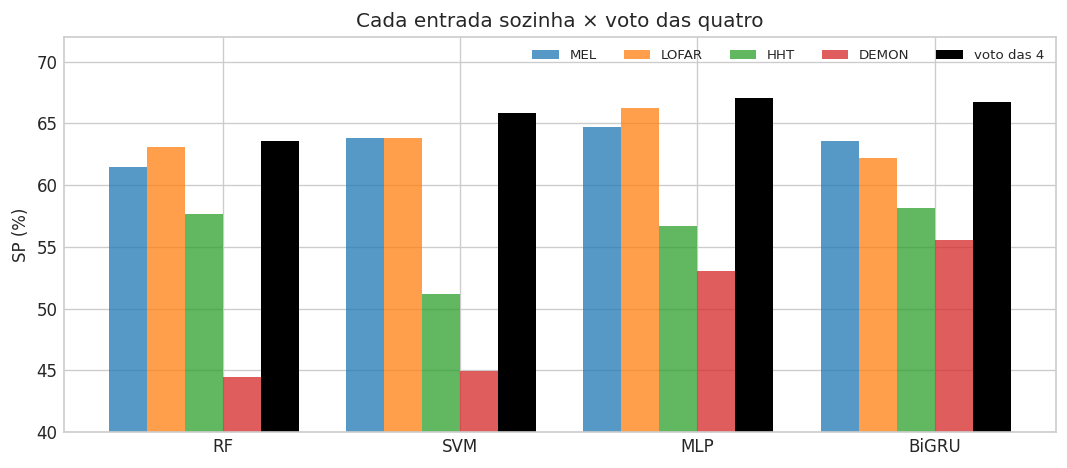

In [4]:
VOTO = {f: por_fold(f, lambda d, ex: voto(np.stack([d[e].values for e in ex], 1), d[ex[0]].values)) for f in FAM}
VOTO_SORT = {f: R.majority_vote(FAM[f]) for f in FAM}  # empate sorteado (sensibilidade)
rows = []
for f in FAM:
    r = {'Família': f, 'voto (SP)': VOTO[f].SP.mean(), 'voto ± (folds)': VOTO[f].SP.std(ddof=0),
         'voto, empate sorteado (SP)': VOTO_SORT[f].SP.mean()}
    for e in REP:
        F_, p_ = R.f_test_5x2(VOTO[f].SP.values, SOLO[f][e].SP.values)
        r[f'Δ vs {e}'] = VOTO[f].SP.mean() - SOLO[f][e].SP.mean(); r[f'p vs {e}'] = p_
    rows.append(r)
VT = pd.DataFrame(rows).set_index('Família')
VT['Δ vs melhor entrada'] = VT['voto (SP)'] - EQ.melhor
VT['p vs melhor entrada'] = [VT.loc[f, f'p vs {EQ.loc[f, "melhor entrada"]}'] for f in FAM]
# Correção para testes múltiplos (16 comparações: 4 famílias × 4 entradas): Bonferroni e Holm
PV = pd.Series({(f, e): VT.loc[f, f'p vs {e}'] for f in FAM for e in REP}).sort_values()
m = len(PV)
holm, ok = {}, True
for i, (key, p_) in enumerate(PV.items()):
    ok = ok and p_ <= 0.05 / (m - i)
    holm[key] = ok
MULT = pd.DataFrame({'p': PV, 'Bonferroni (p ≤ 0,05/16)': PV <= 0.05 / m, 'Holm': pd.Series(holm)})
print('Voto majoritário das 4 entradas (empate -> MEL) × cada entrada sozinha (F-test 5×2cv):')
display(VT.round(3))
REC = pd.DataFrame({f: {c: VOTO[f][f'R_{c}'].mean() - SOLO[f][EQ.loc[f, 'melhor entrada']][f'R_{c}'].mean() for c in CLS}
                    for f in FAM}).T
print('Δ recall por classe: voto − melhor entrada da família'); display(REC.round(1))
print('Testes múltiplos (significativo após a correção = True):'); display(MULT.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(FAM))
for i, r in enumerate(REP):
    ax.bar(x + (i - 2) * 0.16, [SOLO[f][r].SP.mean() for f in FAM], 0.16, label=r, alpha=0.75)
ax.bar(x + 2 * 0.16, VT['voto (SP)'], 0.16, label='voto das 4', color='black')
ax.set_xticks(x + 0.08, list(FAM)); ax.set_ylim(40, 72); ax.set_ylabel('SP (%)'); ax.legend(ncol=5, fontsize=8)
ax.set_title('Cada entrada sozinha × voto das quatro'); plt.tight_layout(); plt.show()

**Leitura.**
- **Ganho sobre a melhor entrada da família:** RF +0,52 (p = 0,757, contra LOFAR); SVM +2,01 (p = 0,067, contra LOFAR); MLP +0,79 (p = 0,545, contra LOFAR); BiGRU +3,12 (p = 0,004, contra MEL).
- **No BiGRU, o voto supera cada uma das quatro entradas** (maior p = 0,006) e melhora todas as classes: SMALL +3,7, MEDIUM +0,3, LARGE +3,9, BACKGROUND +4,4.
- **Testes múltiplos:** são 16 comparações (4 famílias × 4 entradas). Com Bonferroni (α = 0,05/16 = 0,0031), o voto do BiGRU continua superando: LOFAR, DEMON; com Holm (menos conservador, controla o mesmo erro): MEL, LOFAR, DEMON. Todas as comparações que sobrevivem ao Holm: RF vs DEMON, BiGRU vs DEMON, SVM vs DEMON, BiGRU vs LOFAR, MLP vs DEMON, BiGRU vs MEL. Ou seja, com Holm o voto do BiGRU supera MEL, LOFAR, DEMON; contra HHT (p = 0,006) a diferença não resiste à correção.
- O desempate sorteado dá SP RF 62,76, SVM 65,80, MLP 66,01, BiGRU 66,72: a conclusão não depende da regra de desempate.

## 4. O melhor voto: BiGRU × MLP

O BiGRU é a família que mais ganha com o voto; o MLP tem a melhor entrada isolada (LOFAR). Qual chega mais alto?

In [5]:
# BiGRU × MLP: os dois melhores votos, nas gravações comuns às 8 configurações
allx = FAM['BiGRU'] + FAM['MLP']
vb, vm = [], []
for k, d in R.aligned(allx).items():
    y = d.Target.values
    for lst, ex in ((vb, FAM['BiGRU']), (vm, FAM['MLP'])):
        lst.append(metr(y, voto(np.stack([d[e].values for e in ex], 1), d[ex[0]].values))['SP'])
F_BM, P_BM = R.f_test_5x2(np.array(vb), np.array(vm))
print(f'voto BiGRU {np.mean(vb):.2f} ± {np.std(vb):.2f} | voto MLP {np.mean(vm):.2f} ± {np.std(vm):.2f} | '
      f'Δ {np.mean(vb) - np.mean(vm):+.2f}, F = {F_BM:.2f}, p = {P_BM:.3f}')
VB_M, VM_M = np.mean(vb), np.mean(vm)

voto BiGRU 66.73 ± 1.24 | voto MLP 67.04 ± 2.07 | Δ -0.31, F = 0.77, p = 0.661


**Leitura.**
- Voto BiGRU 66,73 × voto MLP 67,04: Δ = -0,31, p = 0,661. **Empatam.**
- O BiGRU ganha mais com o voto porque parte de entradas mais fracas e mais parecidas entre si (havia mais o que corrigir); o MLP já tem o LOFAR forte. **Ganhar mais com o ensemble não é o mesmo que chegar mais alto.**

## 5. Uma regra feita à mão: MEL = MEDIUM e LOFAR/HHT = LARGE → SMALL?

Nas gravações SMALL que o MEL erra, ele costuma dizer MEDIUM e LOFAR/HHT costumam dizer LARGE (Notebook 32). A regra "quando aparecer esse padrão, é SMALL" funciona? Olhamos **todas** as gravações de teste em que o padrão aparece, não só as SMALL.

In [6]:
REGRAS = {
    'MEL=MEDIUM e LOFAR=LARGE e HHT=LARGE': lambda m, l, h: (m == MEDIUM) & (l == LARGE) & (h == LARGE),
    'MEL=MEDIUM e LOFAR=LARGE': lambda m, l, h: (m == MEDIUM) & (l == LARGE),
    'MEL=MEDIUM e (LOFAR=LARGE ou HHT=LARGE)': lambda m, l, h: (m == MEDIUM) & ((l == LARGE) | (h == LARGE)),
}
rows = []
for f, ex in FAM.items():
    for nome, fn in REGRAS.items():
        cnt = np.zeros(4)
        for d in AL[f].values():
            m = fn(d[ex[0]].values, d[ex[1]].values, d[ex[2]].values)
            cnt += np.bincount(d.Target.values[m], minlength=4)
        rows.append({'Família': f, 'regra': nome, 'vezes (10 folds)': int(cnt.sum()),
                     **{f'% {c}': 100 * cnt[i] / max(cnt.sum(), 1) for i, c in enumerate(CLS)}})
PADRAO = pd.DataFrame(rows).set_index(['Família', 'regra'])
print('Classe verdadeira das gravações em que o padrão aparece (todas as gravações de teste):'); display(PADRAO.round(1))

def aplica(d, ex):
    p = d[ex[0]].values.copy()
    p[REGRAS['MEL=MEDIUM e LOFAR=LARGE e HHT=LARGE'](d[ex[0]].values, d[ex[1]].values, d[ex[2]].values)] = SMALL
    return p
rows = []
for f in FAM:
    rg = por_fold(f, aplica); F_, p_ = R.f_test_5x2(rg.SP.values, SOLO[f]['MEL'].SP.values)
    rows.append({'Família': f, 'SP MEL': SOLO[f]['MEL'].SP.mean(), 'SP com a regra': rg.SP.mean(),
                 'Δ SP': rg.SP.mean() - SOLO[f]['MEL'].SP.mean(), 'p': p_,
                 **{f'Δ recall {c}': rg[f'R_{c}'].mean() - SOLO[f]['MEL'][f'R_{c}'].mean() for c in CLS}})
REGRA = pd.DataFrame(rows).set_index('Família')
print('Trocar a predição do MEL por SMALL quando o padrão aparece:'); display(REGRA.round(3))

Classe verdadeira das gravações em que o padrão aparece (todas as gravações de teste):


vezes (10 folds)  % SMALL  % MEDIUM  % LARGE  % BACKGROUND
Família regra                                                                                              
RF      MEL=MEDIUM e LOFAR=LARGE e HHT=LARGE                  217     29.5      22.1     48.4           0.0
        MEL=MEDIUM e LOFAR=LARGE                              301     27.6      25.6     46.5           0.3
        MEL=MEDIUM e (LOFAR=LARGE ou HHT=LARGE)               456     28.7      29.4     40.8           1.1
SVM     MEL=MEDIUM e LOFAR=LARGE e HHT=LARGE                   83     28.9      16.9     53.0           1.2
        MEL=MEDIUM e LOFAR=LARGE                              301     34.2      25.9     39.2           0.7
        MEL=MEDIUM e (LOFAR=LARGE ou HHT=LARGE)               393     35.4      28.0     36.1           0.5
MLP     MEL=MEDIUM e LOFAR=LARGE e HHT=LARGE                  136     25.0      15.4     58.8           0.7
        MEL=MEDIUM e LOFAR=LARGE                              261     31.0      19.9     48.7           0.4
        MEL=MEDIUM e (LOFAR=LARGE ou HHT=LARGE)               365     35.3      21.1     42.7           0.8
BiGRU   MEL=MEDIUM e LOFAR=LARGE e HHT=LARGE                   93     38.7      19.4     41.9           0.0
        MEL=MEDIUM e LOFAR=LARGE                              238     33.2      29.8     35.3           1.7
        MEL=MEDIUM e (LOFAR=LARGE ou HHT=LARGE)               400     34.5      28.2     35.0           2.2

Trocar a predição do MEL por SMALL quando o padrão aparece:


,SP MEL,SP com a regra,Δ SP,p,Δ recall SMALL,Δ recall MEDIUM,Δ recall LARGE,Δ recall BACKGROUND
Família,,,,,,,,
RF,61.50,61.58,0.08,0.80,3.60,-3.22,0.0,0.0
SVM,63.78,63.89,0.11,0.64,1.35,-0.94,0.0,0.0
MLP,64.74,64.97,0.24,0.68,1.91,-1.41,0.0,0.0
BiGRU,63.60,63.90,0.29,0.57,2.02,-1.21,0.0,0.0


**Leitura.**
- Com o padrão completo (MEL = MEDIUM, LOFAR = LARGE, HHT = LARGE), a gravação é SMALL em RF 29%, SVM 29%, MLP 25%, BiGRU 39% e LARGE em RF 48%, SVM 53%, MLP 59%, BiGRU 42%. **O mais comum é a gravação ser LARGE**: são navios grandes que o MEL confunde com MEDIUM e que LOFAR/HHT acertam.
- **Armadilha da taxa-base:** um padrão comum entre os SMALL errados é ainda mais comum em outras classes.
- Aplicar a regra: recall SMALL +1,3 a +3,6, MEDIUM -3,2 a -0,9; SP +0,08 a +0,29 (p de 0,57 a 0,80).

## 6. Generalizando a regra: tabela de combinações (BKS)

O *Behavior Knowledge Space* (Huang e Suen, 1995) aprende, para **cada combinação** de predições das entradas, a classe mais provável. A tabela é aprendida no outro fold da mesma repetição (a outra metade dos dados) e aplicada no fold de teste, com pesos de classe balanceados; combinações nunca vistas usam a predição do MEL.

In [7]:
def bks(f, usar):
    """Tabela 'combinação de predições -> classe' aprendida no fold k^1 (a outra metade da mesma repetição)
    e aplicada no fold k; pesos de classe balanceados; combinação não vista -> predição do MEL."""
    ex = FAM[f]; rows = []
    for k in range(10):
        tr, te = AL[f][k ^ 1], AL[f][k]
        Ptr = np.stack([tr[ex[i]].values for i in usar], 1); ytr = tr.Target.values
        w = {c: 1 / np.mean(ytr == c) for c in range(4)}
        tab = {}
        for row, yy in zip(map(tuple, Ptr), ytr):
            tab.setdefault(row, np.zeros(4))[yy] += w[yy]
        Pte = np.stack([te[ex[i]].values for i in usar], 1); mel = te[ex[0]].values
        pred = np.array([tab[tuple(r)].argmax() if tuple(r) in tab else m for r, m in zip(Pte, mel)])
        rows.append({'fold': k, **metr(te.Target.values, pred)})
    return pd.DataFrame(rows).set_index('fold')

rows = []
for usar in ([0, 1, 2], [0, 1, 2, 3]):
    nome = ' + '.join(REP[i] for i in usar)
    for f in FAM:
        b = bks(f, usar); F_, p_ = R.f_test_5x2(b.SP.values, SOLO[f]['MEL'].SP.values)
        rows.append({'entradas': nome, 'Família': f, 'combinações possíveis': 4 ** len(usar),
                     'SP MEL': SOLO[f]['MEL'].SP.mean(), 'SP BKS': b.SP.mean(), 'Δ vs MEL': b.SP.mean() - SOLO[f]['MEL'].SP.mean(), 'p': p_,
                     'Δ recall SMALL': b.R_SMALL.mean() - SOLO[f]['MEL'].R_SMALL.mean()})
BKS = pd.DataFrame(rows).set_index(['entradas', 'Família'])
display(BKS.round(3))

combinações possíveis  SP MEL  SP BKS  Δ vs MEL     p  Δ recall SMALL
entradas                  Família                                                                       
MEL + LOFAR + HHT         RF                          64   61.50   63.98      2.47  0.34           -3.76
                          SVM                         64   63.78   62.46     -1.32  0.30           -3.65
                          MLP                         64   64.74   64.37     -0.37  0.36            2.02
                          BiGRU                       64   63.60   63.19     -0.41  0.55            4.04
MEL + LOFAR + HHT + DEMON RF                         256   61.50   61.65      0.15  0.60           -6.12
                          SVM                        256   63.78   61.96     -1.83  0.23           -4.44
                          MLP                        256   64.74   62.86     -1.88  0.13           -1.40
                          BiGRU                      256   63.60   62.80     -0.80  0.40            1.18

**Leitura.**
- Δ contra o MEL de -1,88 a +2,47 pontos; 0 de 8 comparações com p < 0,05.
- Com 3 entradas há 64 combinações possíveis, com 4 há 256, para ~640 gravações de teste por fold: muitas combinações têm poucas gravações, e a tabela decora ruído. O voto, que não aprende nada, é mais robusto.

## 7. Diversidade, equilíbrio e ganho

,Q médio (erros),κ de Fleiss (acerto/erro),κ de Cohen (classes),amplitude das entradas,pior entrada (SP),melhor entrada (SP),voto (SP),ganho do voto sobre a melhor,p
RF,0.63,0.35,0.43,18.63,44.44,63.07,63.60,0.53,7.57e-01
SVM,0.63,0.35,0.39,18.88,44.95,63.83,65.84,2.01,6.70e-02
MLP,0.68,0.38,0.44,13.18,53.06,66.24,67.04,0.79,5.45e-01
BiGRU,0.60,0.33,0.41,8.06,55.54,63.60,66.73,3.12,4.00e-03


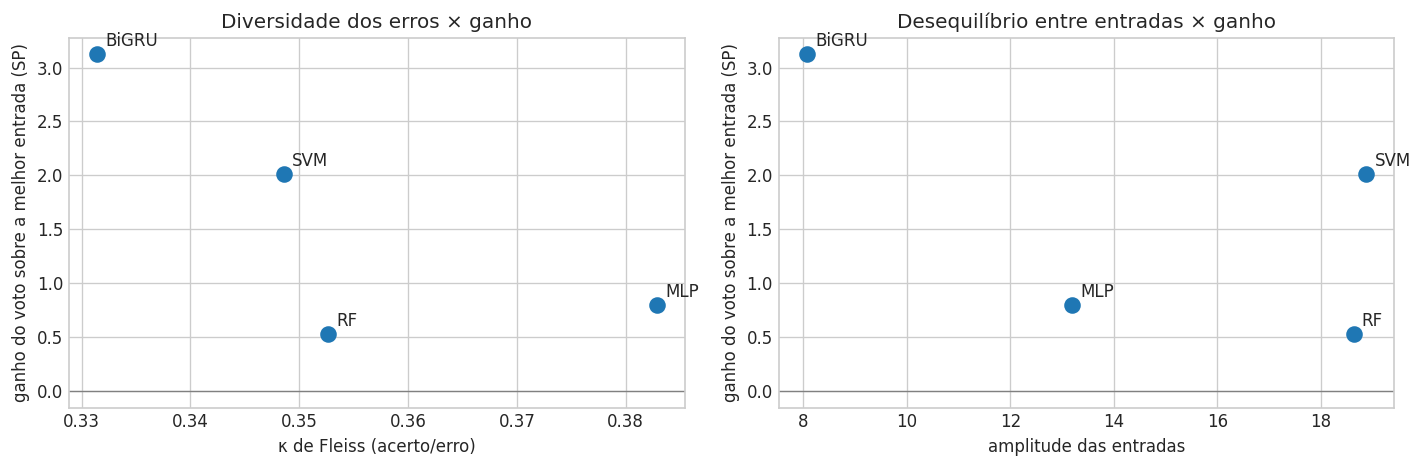

In [8]:
RES = pd.DataFrame({'Q médio (erros)': DIV['Q (erros)'], 'κ de Fleiss (acerto/erro)': DIV['κ de Fleiss (acerto/erro)'],
                    'κ de Cohen (classes)': DIV['κ de Cohen (classes)'], 'amplitude das entradas': EQ['amplitude (melhor − pior)'],
                    'pior entrada (SP)': EQ.pior, 'melhor entrada (SP)': EQ.melhor, 'voto (SP)': VT['voto (SP)'],
                    'ganho do voto sobre a melhor': VT['Δ vs melhor entrada'], 'p': VT['p vs melhor entrada']})
display(RES.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col in zip(ax, ['κ de Fleiss (acerto/erro)', 'amplitude das entradas']):
    a.scatter(RES[col], RES['ganho do voto sobre a melhor'], s=80)
    for f in RES.index:
        a.annotate(f, (RES.loc[f, col], RES.loc[f, 'ganho do voto sobre a melhor']), xytext=(5, 5), textcoords='offset points')
    a.axhline(0, color='gray', lw=0.8); a.set_xlabel(col); a.set_ylabel('ganho do voto sobre a melhor entrada (SP)')
ax[0].set_title('Diversidade dos erros × ganho'); ax[1].set_title('Desequilíbrio entre entradas × ganho')
plt.tight_layout(); plt.show()

**Leitura.**
- O voto ganha onde as duas condições aparecem juntas: **erros pouco correlacionados** e **entradas equilibradas**. RF: Fleiss 0,35, amplitude 18,6, ganho +0,52; SVM: Fleiss 0,35, amplitude 18,9, ganho +2,01; MLP: Fleiss 0,38, amplitude 13,2, ganho +0,79; BiGRU: Fleiss 0,33, amplitude 8,1, ganho +3,12.
- No RF e no SVM a diversidade é parecida com a do BiGRU, mas o DEMON fraco (~45%) atrapalha o voto; no MLP as entradas são as mais correlacionadas e o LOFAR já domina.
- É o que Kuncheva e Whitaker (2003) descrevem: as medidas de diversidade se relacionam de forma fraca com o ganho do ensemble; o que importa é o compromisso entre acurácia individual e diversidade. Com 4 famílias, este é um padrão descritivo, não um teste.

## 8. Conclusões

1. **A família com as entradas menos correlacionadas nos erros é o BiGRU**, por pouco. As medidas sobre classes preditas (V, κ de Cohen) apontam o SVM, porque nele as entradas erram juntas para classes diferentes — o que não é complementaridade.
2. **O voto majoritário das quatro entradas só dá ganho significativo no BiGRU** (BiGRU: +3,12 pontos sobre a melhor entrada, p = 0,004 sem correção). Com a correção de Holm para as 16 comparações, o ganho sobre MEL, LOFAR, DEMON se mantém. É a combinação de entradas com evidência mais forte até aqui, mas pede confirmação (por exemplo, no split por navio).
3. **Ganhar mais não é chegar mais alto:** o voto do BiGRU empata com o do MLP (66,73 × 67,04, p = 0,661).
4. **Diversidade sozinha não basta:** o voto precisa de entradas equilibradas. Para RF e SVM, melhorar o DEMON vem antes de combinar.
5. **Regras feitas à mão e tabelas de combinações não funcionaram:** a regra MEDIUM/LARGE cai na armadilha da taxa-base; o BKS decora ruído.

**Limites:**
- Split por gravação (`ID`), como no artigo; o Notebook 29 mostrou que ele infla os resultados em 6–10 pontos de ACC. O ganho do voto precisa ser confirmado no split por navio.
- Vários testes nesta análise; os resultados além do BiGRU são exploratórios.
- No MLP, MEL/LOFAR (0,512 s) e HHT/DEMON (5 s) vêm de pipelines diferentes.
- A CNN fica de fora: não tem as 4 entradas avaliadas no mesmo protocolo (as CNNs MEL e LOFAR do artigo terminaram de treinar depois desta análise; a CNN HHT e a DEMON são ad hoc; incluir a CNN fica como trabalho futuro).
- Combinar famílias diferentes (ex.: MLP LOFAR + BiGRU MEL) não foi testado; exigiria escolher os membros dentro de cada fold para não inflar o ganho.